Bohr radius a0 = 0.5289 Å
n = 1: E_1 = -13.6139 eV
n = 2: E_2 = -3.4035 eV


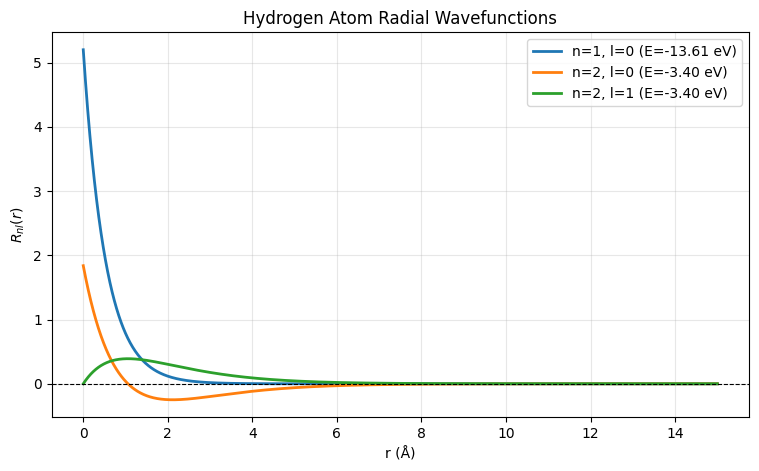

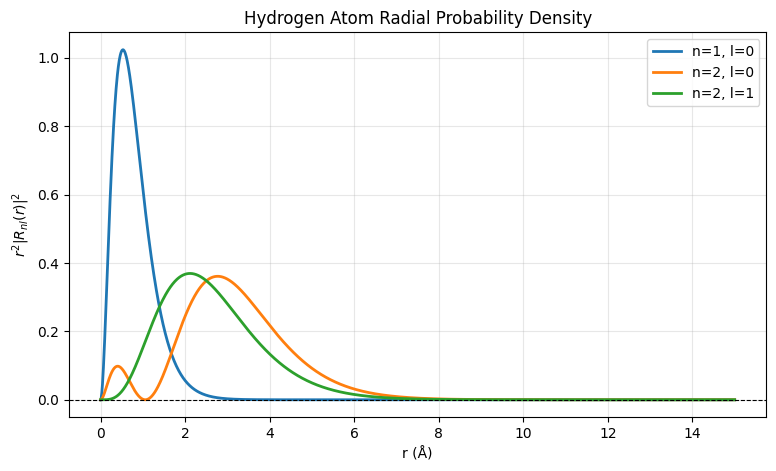

In [2]:
import numpy as np
import matplotlib.pyplot as plt

e = 3.795
hbar_c = 1973.0
m = 0.511e6

a0 = (hbar_c**2) / (m * e**2)

def energy_eigenvalue(n):
    return -(m * e**4) / (2.0 * (hbar_c**2) * (n**2))

def radial_coeffs(n, l):
    j_max = n - l - 1
    c = np.zeros(j_max + 1)
    c[0] = 1.0
    for j in range(j_max):
        c[j + 1] = (2.0 * (j + l + 1 - n) / ((j + 1) * (j + 2 * l + 2))) * c[j]
    return c

def radial_wavefunction(r, n, l):
    rho = r / (n * a0)
    c = radial_coeffs(n, l)
    v_rho = np.polyval(c[::-1], rho)
    R_unnorm = (rho**(l + 1) * np.exp(-rho) * v_rho) / r
    dr = r[1] - r[0]
    norm = np.sqrt(np.sum((R_unnorm**2) * (r**2)) * dr)
    return R_unnorm / norm

print(f"Bohr radius a0 = {a0:.4f} Å")
for n in [1, 2]:
    print(f"n = {n}: E_{n} = {energy_eigenvalue(n):.4f} eV")

r = np.linspace(1e-5, 15.0, 2000)
states = [(1, 0), (2, 0), (2, 1)]

plt.figure(figsize=(9, 5))
for n, l in states:
    R = radial_wavefunction(r, n, l)
    plt.plot(r, R, label=f"n={n}, l={l} (E={energy_eigenvalue(n):.2f} eV)", linewidth=2)

plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Hydrogen Atom Radial Wavefunctions")
plt.xlabel("r (Å)")
plt.ylabel(r"$R_{nl}(r)$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(9, 5))
for n, l in states:
    R = radial_wavefunction(r, n, l)
    P = (r**2) * (R**2)
    plt.plot(r, P, label=f"n={n}, l={l}", linewidth=2)

plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Hydrogen Atom Radial Probability Density")
plt.xlabel("r (Å)")
plt.ylabel(r"$r^2 |R_{nl}(r)|^2$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()